In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import FeatureUnion, make_pipeline as sk_make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, GroupKFold, cross_validate
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score, accuracy_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, get_scorer)
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from imblearn.pipeline import Pipeline          # imblearn Pipeline: resampling happens only on training folds
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## 1. Load the train/test split and define the feature sets


In [2]:
train = pd.read_csv("../results/outputs/processed_dataset_train.csv")
test  = pd.read_csv("../results/outputs/processed_dataset_test.csv")
print("train:", train.shape, " test:", test.shape)

TARGET = "next_risk_class"
NON_FEATURES = ["patient_id", "timestamp", "date", "time", "code", "code_description",
                "risk_class",           # current band - circular with glucose_mg_dl
                "next_glucose",         # the next reading itself - would leak the answer
                "daily_total_insulin",  # whole-day total - includes insulin given AFTER this reading
                "reading_index",        # position in the patient's record - not physiology (see Section 8/10 evidence)
                TARGET]

PIPELINE_PCS = [c for c in train.columns if c.startswith("PC")]   # computed with the leaky column - not used
FEATURES = [c for c in train.columns if c not in NON_FEATURES and c not in PIPELINE_PCS]
print(f"{len(FEATURES)} clean input features (pipeline PC columns excluded: {len(PIPELINE_PCS)})")
print(FEATURES)

y_train, y_test = train[TARGET], test[TARGET]
groups_train = train["patient_id"]

print("\nClass distribution (train):")
print(y_train.value_counts(normalize=True).round(3))

train: (10635, 49)  test: (2659, 49)
21 clean input features (pipeline PC columns excluded: 17)
['hour', 'is_weekend', 'glucose_mg_dl', 'prev_glucose', 'hours_since_prev', 'rolling_mean_3', 'rolling_std_3', 'insulin_regular_6h', 'insulin_nph_6h', 'insulin_ultralente_6h', 'meals_6h', 'exercise_6h', 'hypo_symptoms_6h', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified']

Class distribution (train):
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64


In [3]:
# Evidence for dropping daily_total_insulin: it has ONE value per patient per day, even on days with several
# readings - so a morning reading already "knows" the evening's doses.
per_day = train.groupby(["patient_id", "date"])["daily_total_insulin"].nunique()
readings = train.groupby(["patient_id", "date"]).size()
print("patient-days with a single daily_total_insulin value:", f"{(per_day == 1).mean():.1%}")
print("...of which have more than one reading that day     :", f"{(readings[per_day == 1] > 1).mean():.1%}")

patient-days with a single daily_total_insulin value: 100.0%
...of which have more than one reading that day     : 89.4%


## 2. Why K-Nearest Neighbours suits this problem


In [4]:
# Evidence that scaling matters: the spread of the input features differs a lot, and KNN works on distances
spread = train[FEATURES].std().sort_values(ascending=False)
print("Largest and smallest feature standard deviations in the processed data:")
print(pd.concat([spread.head(4), spread.tail(3)]).round(3).to_string())

Largest and smallest feature standard deviations in the processed data:
insulin_ultralente_6h    6.050
insulin_nph_6h           3.093
hours_since_prev         0.960
glucose_mg_dl            0.715
ctx_post_meal            0.149
hypo_symptoms_6h         0.138
exercise_6h              0.122


## 3. Evaluation metrics


In [5]:
HYPO = "Hypoglycemic"

# Small wrappers score only the Hypoglycemic class. (Passing labels=... straight into make_scorer
# fails on string class names, because the scorer defaults to pos_label=1.)
def hypo_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_f2(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=2, labels=[HYPO], average="macro", zero_division=0)

scoring = {
    "balanced_acc":   "balanced_accuracy",
    "hypo_f2":        make_scorer(hypo_f2),
    "hypo_recall":    make_scorer(hypo_recall),
    "hypo_precision": make_scorer(hypo_precision),
    "macro_f1":       "f1_macro",
    "accuracy":       "accuracy",
    "roc_auc_ovr":    "roc_auc_ovr",   # macro one-vs-rest ROC AUC from predicted probabilities
}

def test_metrics(y_true, y_pred):
    return {
        "balanced_acc":   balanced_accuracy_score(y_true, y_pred),
        "hypo_recall":    hypo_recall(y_true, y_pred),
        "hypo_precision": hypo_precision(y_true, y_pred),
        "hypo_f2":        hypo_f2(y_true, y_pred),
        "accuracy":       accuracy_score(y_true, y_pred),
        "macro_f1":       f1_score(y_true, y_pred, average="macro"),
    }

**Why not tune on hypo F2 or hypo recall?** Two trivial "models" show the problem. Predicting *every* reading as
Hypoglycemic gets hypo-recall 1.0 and a high hypo-F2, while balanced accuracy gives both trivial models exactly
0.333. Section 5 compares this trivial hypo-F2 against every trained model.

In [6]:
trivial = pd.DataFrame([
    {"model": "always Hypoglycemic", **test_metrics(y_train, np.full(len(y_train), HYPO))},
    {"model": "always Normal",       **test_metrics(y_train, np.full(len(y_train), "Normal"))},
]).round(3)
TRIVIAL_HYPO_F2 = trivial.loc[0, "hypo_f2"]
print(trivial.to_string())

                 model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
0  always Hypoglycemic         0.333          1.0           0.116    0.396     0.116     0.069
1        always Normal         0.333          0.0           0.000    0.000     0.523     0.229


## 4. Hyperparameter tuning — GridSearchCV


In [7]:
# StandardScaler -> PCA(95% variance). imblearn does not allow a Pipeline as an intermediate step,
# so the block is wrapped in a FeatureUnion (which imblearn accepts).
def pca_block():
    return sk_make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=RANDOM_STATE))

FEATURE_OPTIONS = {
    "original": "passthrough",
    "pca":      FeatureUnion([("pcs", pca_block())]),
    "all":      FeatureUnion([("original", "passthrough"), ("pcs", pca_block())]),
}

pipe = Pipeline([
    ("features", "passthrough"),
    ("scaler",   StandardScaler()),
    ("sampler",  "passthrough"),
    ("clf",      KNeighborsClassifier()),
])

param_grid = {"features": list(FEATURE_OPTIONS.values()),
              "scaler":   [StandardScaler(), "passthrough"],
              "sampler":  ["passthrough", SMOTE(random_state=RANDOM_STATE), RandomUnderSampler(random_state=RANDOM_STATE)],
              "clf__n_neighbors": [5, 25, 100],
              "clf__weights":     ["uniform", "distance"]}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs = GridSearchCV(pipe, param_grid, scoring=scoring, refit=False, cv=cv, n_jobs=-1,
                  return_train_score=True,   # training-fold scores (inflated for KNN, see above)
                  error_score="raise")       # fail loudly instead of silently returning NaN
gs.fit(train[FEATURES], y_train)

def feature_set_name(step):
    if isinstance(step, str): return "original"
    return "all" if len(step.transformer_list) == 2 else "pca"

cv_all = pd.DataFrame(gs.cv_results_)
cv_all["feature_set"] = cv_all["param_features"].apply(feature_set_name)
print(cv_all.groupby("feature_set")["mean_test_balanced_acc"].max().round(3).rename("best CV balanced acc"))
print("\nTotal configurations evaluated:", len(cv_all))

feature_set
all         0.530
original    0.538
pca         0.523
Name: best CV balanced acc, dtype: float64

Total configurations evaluated: 108


## 5. Comparison across varieties (cross-validation, training set)
Each row below is one **variety** = feature set × scaling × imbalance strategy, shown with its best `n_neighbors` and
`weights` (18 varieties, each tuned over 6 neighbour settings).

In [8]:
def strategy(sampler):
    if isinstance(sampler, SMOTE): return "SMOTE"
    if isinstance(sampler, RandomUnderSampler): return "Undersampling"
    return "None"

cv_all["imbalance"] = cv_all["param_sampler"].apply(strategy)
cv_all["scaling"] = cv_all["param_scaler"].apply(lambda s: "none" if isinstance(s, str) else "StandardScaler")
cv_all["k"] = cv_all["param_clf__n_neighbors"].astype(int)
cv_all["weights"] = cv_all["param_clf__weights"].astype(str)

metric_cols = ["mean_test_balanced_acc", "std_test_balanced_acc", "mean_test_hypo_f2", "mean_test_hypo_recall",
               "mean_test_hypo_precision", "mean_test_macro_f1", "mean_test_accuracy", "mean_test_roc_auc_ovr"]
best_per_variety = (cv_all.sort_values("mean_test_balanced_acc", ascending=False)
                          .groupby(["feature_set", "scaling", "imbalance"], as_index=False).first())
varieties = (best_per_variety[["feature_set", "scaling", "imbalance", "k", "weights"] + metric_cols]
             .rename(columns=lambda c: c.replace("mean_test_", ""))
             .sort_values("balanced_acc", ascending=False).reset_index(drop=True))
print(f"{len(varieties)} varieties (each tuned over {cv_all.groupby(['feature_set', 'scaling', 'imbalance']).size().iloc[0]} neighbour settings)")
print(varieties.round(3).to_string())

18 varieties (each tuned over 6 neighbour settings)
   feature_set         scaling      imbalance    k   weights  balanced_acc  std_test_balanced_acc  hypo_f2  hypo_recall  hypo_precision  macro_f1  accuracy  roc_auc_ovr
0     original            none          SMOTE  100  distance         0.538                  0.011    0.446        0.589           0.226     0.487     0.519        0.720
1          all            none          SMOTE  100  distance         0.530                  0.007    0.437        0.584           0.218     0.479     0.509        0.717
2     original  StandardScaler          SMOTE  100  distance         0.527                  0.004    0.425        0.565           0.214     0.478     0.511        0.713
3          all  StandardScaler          SMOTE  100  distance         0.525                  0.004    0.431        0.576           0.215     0.475     0.506        0.712
4          pca            none          SMOTE  100  distance         0.523                  0.008    0.

In [9]:
# Effect of each choice, averaged over the other settings (best neighbour settings per variety)
cols_show = ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "macro_f1", "accuracy"]
handled = varieties[varieties.imbalance != "None"]
print(varieties.groupby("imbalance")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False).to_string(), "\n")
print(handled.groupby("scaling")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False).to_string(), "\n")
print(handled.groupby("feature_set")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False).to_string(), "\n")

print(f"Trivial 'always Hypoglycemic' hypo-F2 : {TRIVIAL_HYPO_F2:.3f}")
print(f"Best hypo-F2 of any trained model     : {cv_all['mean_test_hypo_f2'].max():.3f}")
print("-> tuning on hypo-F2 would have rewarded the trivial model over every real one"
      if TRIVIAL_HYPO_F2 > cv_all['mean_test_hypo_f2'].max() else
      "-> here the best trained model edges past the trivial one, but only just")

               balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  accuracy
imbalance                                                                            
SMOTE                 0.527        0.572           0.215    0.430     0.477     0.509
Undersampling         0.491        0.512           0.207    0.395     0.451     0.489
None                  0.473        0.210           0.353    0.229     0.481     0.576 

                balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  accuracy
scaling                                                                               
none                   0.512        0.547           0.214    0.417     0.467     0.500
StandardScaler         0.505        0.536           0.208    0.407     0.462     0.497 

             balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  accuracy
feature_set                                                                        
original            0.513        0.547           0

## 6. Choosing the final model 

In [10]:
N_FOLDS = cv.get_n_splits()
cv_all["se_bal"] = cv_all["std_test_balanced_acc"] / np.sqrt(N_FOLDS)
top = cv_all.loc[cv_all["mean_test_balanced_acc"].idxmax()]
threshold = top["mean_test_balanced_acc"] - top["se_bal"]

IMB_RANK = {"Undersampling": 0, "SMOTE": 1, "None": 2}
FS_RANK  = {"original": 0, "pca": 1, "all": 2}
SC_RANK  = {"StandardScaler": 0, "none": 1}
W_RANK   = {"uniform": 0, "distance": 1}

tied = cv_all[cv_all["mean_test_balanced_acc"] >= threshold].copy()
tied["rank"] = list(zip(tied.imbalance.map(IMB_RANK), tied.feature_set.map(FS_RANK), tied.scaling.map(SC_RANK),
                        -tied.k, tied.weights.map(W_RANK), -tied.mean_test_balanced_acc))
chosen = tied.sort_values("rank").iloc[0]

def describe(r):
    return f"{r.feature_set} features, {r.scaling} scaling, {r.imbalance}, k={r.k}, weights={r.weights}"

print(f"Highest CV balanced acc : {top.mean_test_balanced_acc:.4f}  ({describe(top)})")
print(f"One-SE threshold        : {threshold:.4f}   -> {len(tied)} of {len(cv_all)} configurations within one standard error of the best")
print(f"Chosen (first by preference)  : {chosen.mean_test_balanced_acc:.4f} ± {chosen.std_test_balanced_acc:.4f}  ({describe(chosen)})")
print("\nCompetitive configurations by imbalance strategy:")
print(tied.groupby("imbalance").size().to_string())
chosen_params = cv_all.loc[chosen.name, "params"]

Highest CV balanced acc : 0.5382  (original features, none scaling, SMOTE, k=100, weights=distance)
One-SE threshold        : 0.5335   -> 1 of 108 configurations within one standard error of the best
Chosen (first by preference)  : 0.5382 ± 0.0105  (original features, none scaling, SMOTE, k=100, weights=distance)

Competitive configurations by imbalance strategy:
imbalance
SMOTE    1


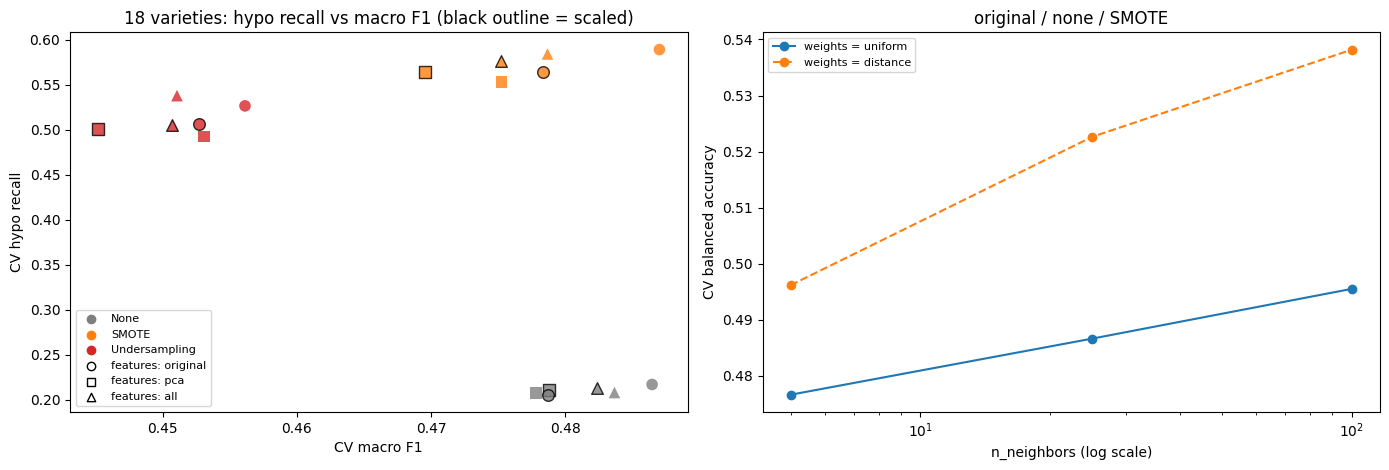

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) hypo-recall vs macro-F1 for every variety - the trade-off the imbalance strategies create
markers = {"original": "o", "pca": "s", "all": "^"}
colors = {"None": "tab:gray", "SMOTE": "tab:orange", "Undersampling": "tab:red"}
for _, r in varieties.iterrows():
    axes[0].scatter(r.macro_f1, r.hypo_recall, marker=markers[r.feature_set], color=colors[r.imbalance], s=70, alpha=0.8,
                    edgecolor="black" if r.scaling == "StandardScaler" else "none")
for k, c in colors.items():
    axes[0].scatter([], [], color=c, label=k)
for k, m in markers.items():
    axes[0].scatter([], [], marker=m, color="white", edgecolor="black", label=f"features: {k}")
axes[0].set_xlabel("CV macro F1"); axes[0].set_ylabel("CV hypo recall")
axes[0].set_title(f"{len(varieties)} varieties: hypo recall vs macro F1 (black outline = scaled)")
axes[0].legend(fontsize=8, loc="best")

# (b) number of neighbours x weighting for the chosen feature set / scaling / imbalance strategy
sub = cv_all[(cv_all.feature_set == chosen.feature_set) & (cv_all.scaling == chosen.scaling) &
             (cv_all.imbalance == chosen.imbalance)]
for w, style in [("uniform", "-"), ("distance", "--")]:
    s_w = sub[sub.weights == w].sort_values("k")
    axes[1].plot(s_w.k, s_w.mean_test_balanced_acc, style, marker="o", label=f"weights = {w}")
axes[1].set_xscale("log"); axes[1].set_xlabel("n_neighbors (log scale)"); axes[1].set_ylabel("CV balanced accuracy")
axes[1].set_title(f"{chosen.feature_set} / {chosen.scaling} / {chosen.imbalance}"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### How many neighbours? — the `k` experiment
The chosen configuration is re-scored with `k` from 1 to 400 (same 5 folds). With `k = 1` a reading is predicted by its
single nearest neighbour, which memorises the training data; as `k` grows the prediction becomes smoother. Training scores
are shown too, but remember they are inflated for KNN because each training row is its own nearest neighbour.

  k  train  validation  validation std  train - validation gap
  1    1.0      0.4667          0.0133                  0.5333
  3    1.0      0.4918          0.0147                  0.5082
  5    1.0      0.4962          0.0145                  0.5038
 10    1.0      0.5045          0.0108                  0.4955
 25    1.0      0.5226          0.0068                  0.4774
 50    1.0      0.5319          0.0095                  0.4681
100    1.0      0.5382          0.0105                  0.4618
200    1.0      0.5353          0.0084                  0.4647
400    1.0      0.5302          0.0082                  0.4698


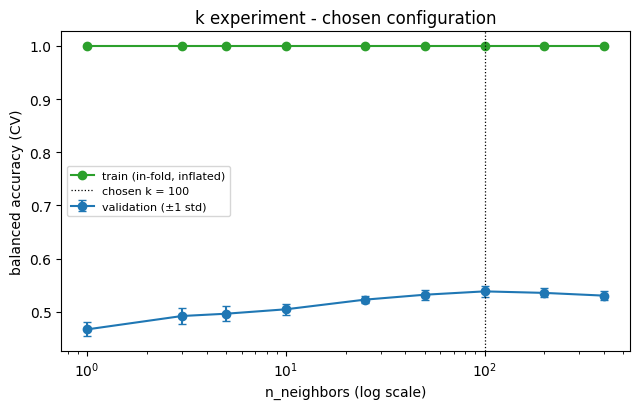

In [12]:
K_VALUES = [1, 3, 5, 10, 25, 50, 100, 200, 400]
rows = []
for k in K_VALUES:
    m = clone(pipe).set_params(**{**chosen_params, "clf__n_neighbors": k})
    r = cross_validate(m, train[FEATURES], y_train, cv=cv, scoring="balanced_accuracy", return_train_score=True, n_jobs=-1)
    rows.append({"k": k, "train": r["train_score"].mean(), "validation": r["test_score"].mean(),
                 "validation std": r["test_score"].std()})
k_curve = pd.DataFrame(rows)
k_curve["train - validation gap"] = k_curve["train"] - k_curve["validation"]
print(k_curve.round(4).to_string(index=False))

plt.figure(figsize=(6.5, 4.2))
plt.plot(k_curve.k, k_curve.train, marker="o", color="tab:green", label="train (in-fold, inflated)")
plt.errorbar(k_curve.k, k_curve.validation, yerr=k_curve["validation std"], marker="o", color="tab:blue", capsize=3,
             label="validation (±1 std)")
plt.axvline(chosen.k, color="black", ls=":", lw=0.9, label=f"chosen k = {chosen.k}")
plt.xscale("log"); plt.xlabel("n_neighbors (log scale)"); plt.ylabel("balanced accuracy (CV)")
plt.title("k experiment - chosen configuration"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Final model — refit on the full training set, evaluated once on the test set
The chosen configuration is rebuilt from its parameters, refit on all training rows, and evaluated on the test set.

Final model: original features, none scaling, SMOTE, k=100, weights=distance

               precision    recall  f1-score   support

Hyperglycemic      0.558     0.529     0.543       960
 Hypoglycemic      0.224     0.555     0.319       308
       Normal      0.711     0.503     0.589      1391

     accuracy                          0.519      2659
    macro avg      0.497     0.529     0.484      2659
 weighted avg      0.599     0.519     0.541      2659



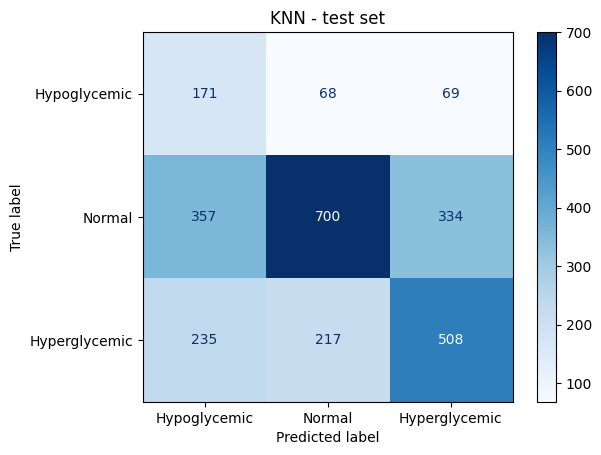

In [13]:
final_model = clone(pipe).set_params(**chosen_params).fit(train[FEATURES], y_train)
print("Final model:", describe(chosen))

y_pred = final_model.predict(test[FEATURES])
print("\n" + classification_report(y_test, y_pred, digits=3))

LABELS = ["Hypoglycemic", "Normal", "Hyperglycemic"]
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS), display_labels=LABELS).plot(cmap="Blues")
plt.title("KNN - test set"); plt.show()

In [14]:
final_row = {"model": "KNN (tuned, chosen)", **test_metrics(y_test, y_pred)}

# Untuned KNN: scikit-learn defaults (k = 5, uniform weights), raw unscaled features, no imbalance handling
default_knn = KNeighborsClassifier().fit(train[FEATURES], y_train)
default_row = {"model": "KNN (untuned defaults)", **test_metrics(y_test, default_knn.predict(test[FEATURES]))}

SAVED = [("Gradient Boosting (Model 5, tuned)", "model_results_gradient_boosting.csv"),
         ("SVM RBF (Model 4, tuned)", "model_results_svm.csv"),
         ("Random Forest (Model 3, tuned)", "model_results_random_forest.csv"),
         ("Decision Tree (Model 2, tuned)", "model_results_decision_tree.csv"),
         ("Logistic Regression (Model 1, tuned)", "model_results_logistic_regression.csv")]
rows = [default_row, final_row]
for label, path in SAVED:
    try:   # saved by the Model 1-5 notebooks: same features, same protocol, same test set
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        rows.append({"model": label, **{m: saved[m] for m in ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]}})
    except FileNotFoundError:
        print(f"({path} not found - run that notebook to add its row to this table.)")

comparison = pd.DataFrame(rows)
print(comparison[["model", "balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]]
      .round(3).to_string(index=False))

                               model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
              KNN (untuned defaults)         0.441        0.127           0.229    0.139     0.555     0.442
                 KNN (tuned, chosen)         0.529        0.555           0.224    0.429     0.519     0.484
  Gradient Boosting (Model 5, tuned)         0.504        0.455           0.217    0.373     0.513     0.471
            SVM RBF (Model 4, tuned)         0.507        0.523           0.216    0.407     0.495     0.462
      Random Forest (Model 3, tuned)         0.503        0.416           0.234    0.360     0.521     0.475
      Decision Tree (Model 2, tuned)         0.485        0.565           0.180    0.396     0.449     0.428
Logistic Regression (Model 1, tuned)         0.478        0.519           0.182    0.379     0.461     0.433


In [15]:
# What the hypo precision means in practice on the test set
n_alarms = int((y_pred == HYPO).sum())
n_true = int(((y_pred == HYPO) & (y_test == HYPO)).sum())
base_rate = (y_test == HYPO).mean()
alarm = {
    "hypo alarms raised":             n_alarms,
    "share of all readings flagged":  f"{n_alarms / len(y_test):.1%}",
    "real hypo events caught":        f"{n_true} of {int((y_test == HYPO).sum())}",
    "false alarms per real hypo":     f"{(n_alarms - n_true) / max(n_true, 1):.1f}",
    "precision vs base rate (lift)":  f"{(n_true / max(n_alarms, 1)) / base_rate:.2f}x",
}
print(pd.Series(alarm, name="value").to_frame().to_string())

                                    value
hypo alarms raised                    763
share of all readings flagged       28.7%
real hypo events caught        171 of 308
false alarms per real hypo            3.5
precision vs base rate (lift)       1.93x


### Comparing operating points — hypo recall at the same share of flagged readings
Hypo recall depends on how many readings a model chooses to flag, so a model that flags fewer readings can show lower
recall even when it ranks readings better. To compare like with like, this model's hypo probabilities are ranked and
the top share of readings is flagged, matching the share flagged by each earlier model at its own default rule. KNN
scores tie often (many readings share the same neighbour vote), and ties are broken arbitrarily. (The test labels are
used only to measure recall at flag rates fixed by the other models; nothing is tuned on the test set.)

In [16]:
proba = final_model.predict_proba(test[FEATURES])
classes = list(final_model.classes_)
p_hypo = proba[:, classes.index(HYPO)]
is_hypo = (y_test == HYPO).values

def knn_recall_at(share):
    k = int(round(share * len(y_test)))
    return is_hypo[np.argsort(-p_hypo, kind="stable")[:k]].sum() / is_hypo.sum()

rows = [{"compared with": "KNN itself (sanity check)", "share flagged": n_alarms / len(y_test),
         "that model's hypo recall": final_row["hypo_recall"],
         "KNN hypo recall at that share": knn_recall_at(n_alarms / len(y_test))}]
for label, path in SAVED:
    try:
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        rows.append({"compared with": label, "share flagged": saved["test_flagged_share"],
                     "that model's hypo recall": saved["hypo_recall"],
                     "KNN hypo recall at that share": knn_recall_at(saved["test_flagged_share"])})
    except (FileNotFoundError, KeyError):
        print(f"({path} not found or lacks test_flagged_share - re-run that notebook to add its row.)")
matched = pd.DataFrame(rows)
print(matched.round(3).to_string(index=False))

                       compared with  share flagged  that model's hypo recall  KNN hypo recall at that share
           KNN itself (sanity check)          0.287                     0.555                          0.558
  Gradient Boosting (Model 5, tuned)          0.243                     0.455                          0.510
            SVM RBF (Model 4, tuned)          0.281                     0.523                          0.555
      Random Forest (Model 3, tuned)          0.205                     0.416                          0.464
      Decision Tree (Model 2, tuned)          0.364                     0.565                          0.649
Logistic Regression (Model 1, tuned)          0.330                     0.519                          0.604


### ROC AUC — ranking quality, independent of the threshold
Each curve is one class against the other two. For KNN the score is the share of neighbours in the class, so the curve is
made of a limited number of steps.

Test ROC AUC - Hypoglycemic vs rest : 0.733
Test ROC AUC - macro one-vs-rest    : 0.727


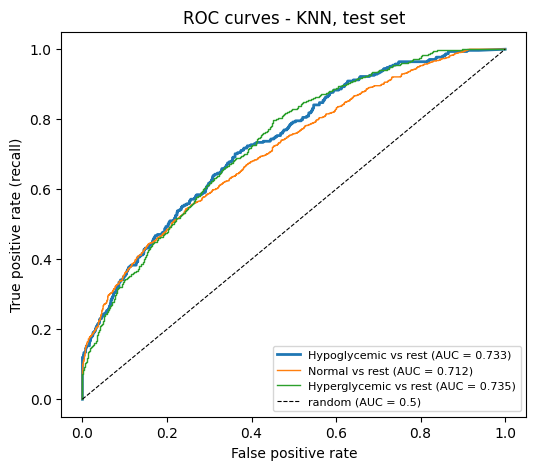

In [17]:
hypo_auc  = roc_auc_score((y_test == HYPO).astype(int), proba[:, classes.index(HYPO)])
macro_auc = roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=classes)
print(f"Test ROC AUC - Hypoglycemic vs rest : {hypo_auc:.3f}")
print(f"Test ROC AUC - macro one-vs-rest    : {macro_auc:.3f}")

plt.figure(figsize=(6, 5))
for c in LABELS:
    fpr, tpr, _ = roc_curve((y_test == c).astype(int), proba[:, classes.index(c)])
    auc_c = roc_auc_score((y_test == c).astype(int), proba[:, classes.index(c)])
    plt.plot(fpr, tpr, label=f"{c} vs rest (AUC = {auc_c:.3f})", lw=2 if c == HYPO else 1)
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves - KNN, test set"); plt.legend(fontsize=8); plt.show()

### Choosing the hypo alarm threshold on training data
The default rule (predict the class with the highest probability or score) is not tuned for catching hypo events. Here the
alarm threshold is chosen from **out-of-fold** hypo scores on the **training set only** — the test set plays no part in
choosing it — for three recall targets, and each resulting rule is applied to the test set once. Which recall level is
acceptable is a clinical decision; the targets only show the trade-off between caught hypo events and false alarms.

In [18]:
score_method = "predict_proba" if hasattr(final_model, "predict_proba") else "decision_function"
hypo_col = list(final_model.classes_).index(HYPO)
oof_scores = cross_val_predict(clone(final_model), train[FEATURES], y_train, cv=cv, method=score_method)[:, hypo_col]
test_hypo_scores = getattr(final_model, score_method)(test[FEATURES])[:, hypo_col]
oof_is_hypo = (y_train == HYPO).values
test_is_hypo = (y_test == HYPO).values

default_flag = (y_pred == HYPO)
rows = [{"rule": "default (highest score wins)", "threshold": np.nan,
         "test hypo recall": test_is_hypo[default_flag].sum() / test_is_hypo.sum(),
         "test hypo precision": test_is_hypo[default_flag].sum() / max(default_flag.sum(), 1),
         "test share flagged": default_flag.mean()}]
order = np.argsort(-oof_scores)
cum_recall = np.cumsum(oof_is_hypo[order]) / oof_is_hypo.sum()
for target in [0.5, 0.6, 0.7]:
    tau = oof_scores[order][np.searchsorted(cum_recall, target)]
    flag = test_hypo_scores >= tau
    rows.append({"rule": f"threshold for out-of-fold recall {target}", "threshold": tau,
                 "test hypo recall": test_is_hypo[flag].sum() / test_is_hypo.sum(),
                 "test hypo precision": test_is_hypo[flag].sum() / max(flag.sum(), 1),
                 "test share flagged": flag.mean()})
threshold_table = pd.DataFrame(rows)
print(threshold_table.round(3).to_string(index=False))
threshold_table.assign(model=final_row["model"]).to_csv(
    "../results/outputs/threshold_analysis_" + str(final_row["model"]).split()[0].lower() + ".csv", index=False)

                                rule  threshold  test hypo recall  test hypo precision  test share flagged
        default (highest score wins)        NaN             0.555                0.224               0.287
threshold for out-of-fold recall 0.5      0.440             0.471                0.250               0.218
threshold for out-of-fold recall 0.6      0.378             0.584                0.219               0.309
threshold for out-of-fold recall 0.7      0.322             0.701                0.201               0.405


## 8. Inside the model — how coarse are KNN's scores?
KNN has no coefficients, rules or importances to show. What can be shown is how limited its scores are: with `k`
neighbours and uniform weights, the hypo probability of a reading can take only `k + 1` different values, and every reading
whose neighbours contain no hypo reading at all gets a score of exactly 0, so those readings cannot be ranked against each
other. Distance weighting gives far finer scores, and the numbers below show how many distinct values this model actually produces. Which features the model depends on is measured by permutation importance in Section 10, on later readings.

In [19]:
print(f"Distinct hypo probability values on the test set: {len(np.unique(p_hypo))} (k = {chosen.k})")
print(f"Share of test readings whose neighbours contain no hypo reading (score exactly 0): {(p_hypo == 0).mean():.1%}")
print(f"Share of test readings tied with at least one other reading at the same hypo score: "
      f"{(pd.Series(p_hypo).map(pd.Series(p_hypo).value_counts()) > 1).mean():.1%}")

Distinct hypo probability values on the test set: 2472 (k = 100)
Share of test readings whose neighbours contain no hypo reading (score exactly 0): 5.6%
Share of test readings tied with at least one other reading at the same hypo score: 7.6%


## 9. Overfitting check — training vs cross-validation vs test
For KNN the training score is not informative on its own: each training row is its own nearest neighbour, so a model with
`k = 1` or with distance weighting scores almost perfectly on the rows it was fitted on. The comparison that matters is
between the **cross-validation score and the test score**, and the `k` experiment in Section 6 shows how the validation
score moves as the model gets smoother. Three scores are compared for the chosen configuration:
- **Train (in-fold):** average score on the training folds during cross-validation (inflated, see above).
- **CV (validation):** average score on the held-out folds.
- **Test:** the final model on the test set.

The same comparison is made for the **untuned** model (defaults on raw features), to show what the tuning bought.

In [20]:
fit_rows = ["balanced_acc", "hypo_recall", "macro_f1", "roc_auc_ovr"]
test_scores = {**test_metrics(y_test, y_pred), "roc_auc_ovr": macro_auc}
overfit = pd.DataFrame({
    "Train (in-fold)":  {m: chosen[f"mean_train_{m}"] for m in fit_rows},
    "CV (validation)":  {m: chosen[f"mean_test_{m}"] for m in fit_rows},
    "Test":             {m: test_scores[m] for m in fit_rows},
})
overfit["train - CV gap"] = overfit["Train (in-fold)"] - overfit["CV (validation)"]
print("Chosen (tuned) model:")
print(overfit.round(3).to_string())

# Untuned model: same folds, same scorers
u = cross_validate(clone(default_knn), train[FEATURES], y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
default_test = {**test_metrics(y_test, default_knn.predict(test[FEATURES])),
                "roc_auc_ovr": roc_auc_score(y_test, default_knn.predict_proba(test[FEATURES]),
                                             multi_class="ovr", average="macro", labels=list(default_knn.classes_))}
overfit_default = pd.DataFrame({
    "Train (in-fold)":  {m: u[f"train_{m}"].mean() for m in fit_rows},
    "CV (validation)":  {m: u[f"test_{m}"].mean() for m in fit_rows},
    "Test":             {m: default_test[m] for m in fit_rows},
})
overfit_default["train - CV gap"] = overfit_default["Train (in-fold)"] - overfit_default["CV (validation)"]
print("\nUntuned model (defaults, raw features):")
print(overfit_default.round(3).to_string())

Chosen (tuned) model:
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc              1.0            0.538  0.529           0.462
hypo_recall               1.0            0.589  0.555           0.411
macro_f1                  1.0            0.487  0.484           0.513
roc_auc_ovr               1.0            0.720  0.727           0.280

Untuned model (defaults, raw features):
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc            0.590            0.438  0.441           0.152
hypo_recall             0.300            0.131  0.127           0.170
macro_f1                0.604            0.439  0.442           0.165
roc_auc_ovr             0.851            0.649  0.651           0.202


## 10. Validation checks — does the row-wise split flatter the scores?


In [21]:
# (a) Time-ordered: each patient's first 80% of readings train, last 20% validate
ordered = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
position = ordered.groupby("patient_id").cumcount()
n_readings = ordered.groupby("patient_id")["patient_id"].transform("size")
is_late = position >= np.floor(n_readings * 0.8)
early, late = ordered[~is_late], ordered[is_late]
print(f"Time-ordered split: {len(early)} earlier readings train / {len(late)} later readings validate "
      f"({late.patient_id.nunique()} patients in both)")
print(pd.DataFrame({"earlier 80%": early[TARGET].value_counts(normalize=True),
                    "later 20%":   late[TARGET].value_counts(normalize=True)}).round(3), "\n")

time_model = clone(final_model).fit(early[FEATURES], early[TARGET])
scorers = {m: (get_scorer(v) if isinstance(v, str) else v) for m, v in scoring.items()}
time_scores = {m: scorers[m](time_model, late[FEATURES], late[TARGET]) for m in scoring}

# (b) Unseen-patient generalisation check: GroupKFold, validation patients never seen in training
group_cv = cross_validate(clone(final_model), train[FEATURES], y_train, groups=groups_train,
                          cv=GroupKFold(n_splits=5), scoring=scoring, n_jobs=-1)

check = pd.DataFrame({
    "Row-wise CV (used for tuning)":     {m: chosen[f"mean_test_{m}"] for m in scoring},
    "Time-ordered (monitored patients)": time_scores,
    "GroupKFold (unseen patients)":      {m: group_cv[f"test_{m}"].mean() for m in scoring},
})
check["time-ordered - row-wise"] = check["Time-ordered (monitored patients)"] - check["Row-wise CV (used for tuning)"]
check["unseen patients - row-wise"] = check["GroupKFold (unseen patients)"] - check["Row-wise CV (used for tuning)"]
print(check.round(3).to_string())

Time-ordered split: 8477 earlier readings train / 2158 later readings validate (70 patients in both)
                 earlier 80%  later 20%
next_risk_class                        
Normal                 0.519      0.540
Hyperglycemic          0.363      0.351
Hypoglycemic           0.117      0.109 

                Row-wise CV (used for tuning)  Time-ordered (monitored patients)  GroupKFold (unseen patients)  time-ordered - row-wise  unseen patients - row-wise
balanced_acc                            0.538                              0.589                         0.496                    0.050                      -0.043
hypo_f2                                 0.446                              0.498                         0.415                    0.053                      -0.031
hypo_recall                             0.589                              0.672                         0.567                    0.083                      -0.022
hypo_precision                          0

### Which features does the model depend on? — permutation importance
Each feature is shuffled in turn and the drop in balanced accuracy is measured. The model trained on each patient's
**earlier** readings is scored on their **later** readings, so this shows what it depends on for predicting the
future. A drop near zero means the feature is not needed for that prediction. The estimate is repeated 10 times per
feature, and the standard deviation shows how noisy it is. Only training-set rows are used, never the test set.
Highly correlated features share credit, so shuffling one at a time understates each.

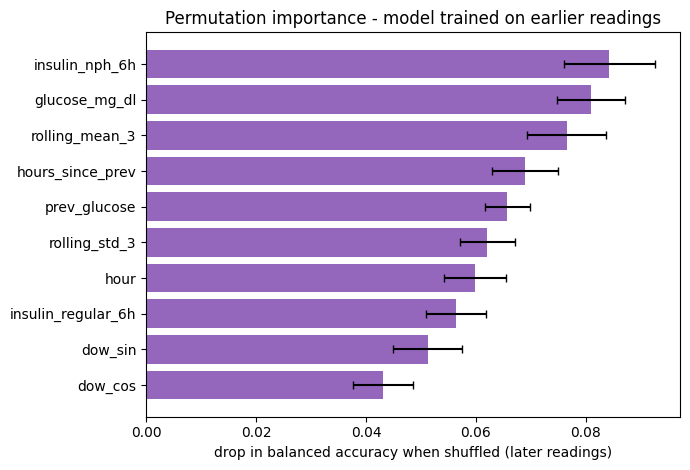

                    permutation drop     std
insulin_nph_6h                0.0843  0.0082
glucose_mg_dl                 0.0810  0.0061
rolling_mean_3                0.0765  0.0072
hours_since_prev              0.0690  0.0060
prev_glucose                  0.0657  0.0041
rolling_std_3                 0.0621  0.0050
hour                          0.0598  0.0056
insulin_regular_6h            0.0563  0.0055
dow_sin                       0.0512  0.0063
dow_cos                       0.0431  0.0055


In [22]:
perm = permutation_importance(time_model, late[FEATURES], late[TARGET], scoring="balanced_accuracy",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_imp.index]
top_perm = perm_imp.head(10)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(range(len(top_perm))[::-1], top_perm.values, xerr=perm_std[top_perm.index].values, color="tab:purple", capsize=3)
ax.set_yticks(range(len(top_perm))[::-1]); ax.set_yticklabels(top_perm.index)
ax.set_xlabel("drop in balanced accuracy when shuffled (later readings)")
ax.set_title("Permutation importance - model trained on earlier readings")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"permutation drop": top_perm.round(4), "std": perm_std[top_perm.index].round(4)}).to_string())

**`reading_index` is excluded from the features.** It is the reading's position in that patient's record (scaled), not a
physiological measurement. Pooled over patients, the hypo share can look as if it falls late in a record, but the two
tables below separate that pattern into its parts: **within** a patient's own record the hypo share barely moves, while
**between** patients it differs clearly, and the highest values of `reading_index` occur only in the patients with the
longest records. The feature therefore partly identifies *which patient* a reading comes from. In time-ordered validation
a patient's later readings receive larger `reading_index` values than any of their earlier ones, so a model that has
learned "large index = lower hypo risk" from the between-patient pattern is most consistent with under-predicting hypo on
future readings. In a separate audit on the training set, removing the feature raised time-ordered hypo recall at each of
three time cut points for each of the five models trained before KNN (15 of 15 comparisons), so it is excluded for all
six models. The sensitivity check at the end of Section 10 adds it back to this model.

In [23]:
ordered_ev = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
n_ev = ordered_ev.groupby("patient_id")["patient_id"].transform("size")
ordered_ev["own_position"] = ordered_ev.groupby("patient_id").cumcount() / n_ev
ordered_ev["hypo_next"] = (ordered_ev[TARGET] == HYPO).astype(int)
ordered_ev["own_fifth"] = pd.cut(ordered_ev["own_position"], [0, 0.2, 0.4, 0.6, 0.8, 1.0], right=False,
                                 labels=["1st", "2nd", "3rd", "4th", "5th"])
print("WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record")
print(ordered_ev.groupby("own_fifth", observed=True)["hypo_next"].mean().round(3).to_string())

per_patient = ordered_ev.groupby("patient_id").agg(readings=("hypo_next", "size"), hypo_share=("hypo_next", "mean"),
                                                   highest_index=("reading_index", "max"))
per_patient["record length"] = pd.qcut(per_patient["readings"], 3, labels=["short", "medium", "long"])
print("\nBETWEEN patients: by length of the patient's record")
print(per_patient.groupby("record length", observed=True).agg(
    patients=("readings", "size"), mean_readings=("readings", "mean"), hypo_share=("hypo_share", "mean"),
    mean_highest_reading_index=("highest_index", "mean")).round(3).to_string())

WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record
own_fifth
1st    0.125
2nd    0.122
3rd    0.123
4th    0.102
5th    0.108

BETWEEN patients: by length of the patient's record
               patients  mean_readings  hypo_share  mean_highest_reading_index
record length                                                                 
short                24         66.833       0.179                      -0.089
medium               23         98.000       0.128                       0.104
long                 23        294.652       0.121                       1.427


### Sensitivity — what happens if `reading_index` is added back?
The protocol excludes `reading_index` (see the explanation above). To see its effect on this model, the chosen configuration
is re-scored with it **added back**, under the same three validation schemes. Only training-set rows are used, never the
test set.

In [24]:
sc_small = {k: scoring[k] for k in ["balanced_acc", "hypo_recall"]}

def evaluate_features(cols):
    row = cross_validate(clone(final_model), train[cols], y_train, cv=cv, scoring=sc_small, n_jobs=-1)
    grp = cross_validate(clone(final_model), train[cols], y_train, groups=groups_train,
                         cv=GroupKFold(n_splits=5), scoring=sc_small, n_jobs=-1)
    tm = clone(final_model).fit(early[cols], early[TARGET])
    return {"row-wise CV balanced acc":    row["test_balanced_acc"].mean(),
            "time-ordered balanced acc":   scorers["balanced_acc"](tm, late[cols], late[TARGET]),
            "time-ordered hypo recall":    scorers["hypo_recall"](tm, late[cols], late[TARGET]),
            "GroupKFold balanced acc":     grp["test_balanced_acc"].mean(),
            "GroupKFold hypo recall":      grp["test_hypo_recall"].mean()}

with_index = FEATURES + ["reading_index"]
ablation = pd.DataFrame({"reading_index excluded (protocol)": evaluate_features(FEATURES),
                         "reading_index added back":          evaluate_features(with_index)})
ablation["change"] = ablation["reading_index added back"] - ablation["reading_index excluded (protocol)"]
print(ablation.round(3).to_string())

                           reading_index excluded (protocol)  reading_index added back  change
row-wise CV balanced acc                               0.538                     0.504  -0.035
time-ordered balanced acc                              0.589                     0.539  -0.049
time-ordered hypo recall                               0.672                     0.617  -0.055
GroupKFold balanced acc                                0.496                     0.462  -0.034
GroupKFold hypo recall                                 0.567                     0.588   0.022


In [25]:
# Save the final result so the group comparison notebook can load all six models in one format
final_out = pd.DataFrame([{**final_row, "n_features": len(FEATURES), "feature_list": ";".join(FEATURES),
                           "feature_set": chosen.feature_set, "scaling": chosen.scaling, "imbalance": chosen.imbalance,
                           "n_neighbors": int(chosen.k), "weights": chosen.weights,
                           "cv_balanced_acc": chosen.mean_test_balanced_acc,
                           "cv_balanced_acc_std": chosen.std_test_balanced_acc,
                           "group_cv_balanced_acc": group_cv["test_balanced_acc"].mean(),
                           "group_cv_hypo_recall": group_cv["test_hypo_recall"].mean(),
                           "time_ordered_balanced_acc": time_scores["balanced_acc"],
                           "time_ordered_hypo_recall": time_scores["hypo_recall"],
                           "test_hypo_auc": hypo_auc, "test_macro_auc": macro_auc,
                           "test_flagged_share": n_alarms / len(y_test),
                           "train_cv_gap_balanced_acc": overfit.loc["balanced_acc", "train - CV gap"]}])
final_out.to_csv("../results/outputs/model_results_knn.csv", index=False)
print(final_out.round(4).T.to_string(header=False))

model                                                                                                                                                                                                                                                                                                    KNN (tuned, chosen)
balanced_acc                                                                                                                                                                                                                                                                                                          0.5292
hypo_recall                                                                                                                                                                                                                                                                                                           0.5552
hypo_precision                                   

## 11. Conclusion, limitations and improvements
*(Interpretation of the generated summary above; every number quoted there comes from this run.)*

**What mattered:**
1. **SMOTE was clearly the best way to handle the imbalance for KNN.** Averaged over the other settings, SMOTE scores 0.527, undersampling 0.491 and no handling 0.473, a spread (0.054) several times the fold-to-fold standard deviation (about 0.008); in the other models the strategies were much closer. Without any handling the KNN varieties catch only about 21% of hypo events on average (precision 0.353). A plausible reason is that with a plain vote hypo readings rarely win a neighbourhood, and the synthetic hypo rows give them a chance; that reason was not tested separately.
2. **A large `k` worked best.** Validation balanced accuracy rises from 0.467 at k = 1 to 0.538 at k = 100, then falls slightly to 0.535 at k = 200 and 0.530 at k = 400. A small `k` follows noise in individual readings; a very large one smooths away real structure.
3. **Scaling did not help.** The unscaled variety scored a little higher (0.512 against 0.505 on average; 0.538 against 0.527 for the best original-feature setting), a difference of about one fold standard deviation. So the chosen model has no scaler, and its neighbour search is dominated by the widest features. The preference order (StandardScaler first) did not decide anything: only one configuration was inside the one-standard-error band, so the chosen model is simply the best-scoring one.
4. **The original features are enough.** Original 0.513, all features 0.510 and PCA 0.503 differ by little; PCA is lowest.
5. **KNN has the highest observed values on the main measures.** Test balanced accuracy 0.529, macro ROC AUC 0.727, row-wise CV 0.538, time-ordered 0.589 and unseen-patient 0.496. Its balanced accuracy is 0.022–0.026 above the SVM, boosting and the forest on the test set, 0.028–0.042 above them in time-ordered validation, and only 0.008–0.024 above them on unseen patients. At each other model's flag rate it also catches more hypo events (0.510 against 0.455 for boosting, 0.555 against 0.523 for the SVM, 0.464 against 0.416 for the forest, 0.649 against 0.565 for the tree, 0.604 against 0.519 for Logistic Regression). Its recall at its own default rule (0.555) is second only to the tree's (0.565), which flags more readings.
6. **Its scores are not coarse.** With distance weighting it produces 2,472 distinct hypo scores, and only 5.6% of test readings have no hypo neighbour at all, so the coarse-score weakness of KNN with uniform weights does not apply to this configuration.
7. **Tuning bought a lot.** The untuned KNN (k = 5, raw features, no imbalance handling) scores a balanced accuracy of 0.441 and catches 12.7% of hypo events.

**Reading the model:**
- KNN has no rules or coefficients. Permutation importance on later readings is spread over many features, with larger drops than for the other models, because the distance uses all 21 at once: `insulin_nph_6h` (0.084), `glucose_mg_dl` (0.081), `rolling_mean_3` (0.077), `hours_since_prev` (0.069) and `prev_glucose` (0.066). Recent glucose history and the NPH insulin dose, one of the widest columns, shape the neighbourhoods most.
- **`reading_index` sensitivity (Section 10).** Adding it back made KNN worse on four of the five measures: row-wise CV 0.538 to 0.504, time-ordered balanced accuracy 0.589 to 0.539, time-ordered hypo recall 0.672 to 0.617 and unseen-patient balanced accuracy 0.496 to 0.462; unseen-patient hypo recall rose slightly (0.567 to 0.588). The balanced-accuracy effects are the largest of the six models, which is consistent with a continuous record-position column adding a patient-specific axis to an unscaled distance.

**Validation checks.** Time-ordered balanced accuracy is 0.589 (+0.050 against the row-wise CV), and unseen-patient balanced accuracy is 0.496 (−0.043, the largest drop of the six models). That fits the explanation in Section 10: KNN predicts from the most similar stored readings, which are often the same patient's, and for an unseen patient there are none. The time-ordered figure is about 0.08 above a baseline that uses no features at all and only each patient's own earlier class frequencies (0.507; group comparison notebook).

**Overfitting check.** The training scores are exactly 1.000 for every `k`, because with distance weighting each training row is its own nearest neighbour, so the in-fold gap (0.462) is meaningless. The comparison that matters is cross-validation against test: 0.538 and 0.529, which agree to within the fold-to-fold noise.

**Limitations:**
- **Highest observed, not shown to be significantly better.** The lead over boosting and the forest on unseen patients (0.008–0.010) is inside the noise, and the lead is largest on the row-wise and time-ordered checks, where the nearest stored readings can come from the same patient.
- **Random resampling:** SMOTE is random, so unlike the class-weight models the fitted KNN can vary slightly between runs and machines.
- **Unscaled distance:** the neighbour search is dominated by the widest columns, and it may partly match patients by their insulin regimen. That was not tested in this notebook.
- **Slow prediction and no model to inspect:** every query is compared with all stored training rows, and there are no rules or coefficients to read.
- **Alarm burden:** about 3.5 false alarms per real hypo event at the default rule, and the threshold analysis shows that reaching 70% recall means flagging about 40% of readings, at about four false alarms per real event.
- **Coarse grid:** `k` of 5, 25 or 100 (plus the separate experiment), two weightings, and the default Euclidean distance was not tuned.
- **Validation for the use case.** The reviewed row-wise split is kept for tuning and testing. The time-ordered figure is the one to quote for future readings of monitored patients; it comes from a single holdout, so differences of a few hundredths are noise. The GroupKFold check shows generalisation to unseen patients.
- **Leakage handled:** `daily_total_insulin` and `reading_index` are excluded, PCA is re-fit inside the pipeline, and the `*_6h` windows were verified as backward-looking in the preprocessing code (they include events logged at the same timestamp as the reading; some timestamps are conventional slot times).
- **Test-set use during development:** nothing was chosen or tuned on the test set, but its results were viewed while the notebook was developed, and the threshold analysis and the matched-flag-rate table use test labels only to evaluate rules chosen on training data or at other models' flag rates.

**Improvements:**
- Check how many of each reading's neighbours come from the same patient, and test whether KNN keeps its lead when the neighbours must come from other patients.
- Tune the distance (for example Manhattan or a different Minkowski power) and a finer range of `k`, and test feature weighting instead of a plain unscaled or scaled distance.
- Use the alarm threshold from Section 7 for a clinically chosen recall instead of the default rule.